In [ ]:
import pandas as pd

earthquakes = pd.read_csv("TT_Earthquakes_for_Python.csv")

print(earthquakes.shape)
print(earthquakes.columns.tolist())

(1360, 25)
['X', 'Y', 'fid', 'time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type', 'horizontalError', 'depthError', 'magError', 'magNst', 'status', 'locationSource', 'magSource']


In [ ]:
# read dates
#first 5 earthquake timestamps
print(earthquakes["time"].head())
#tells us the datatype
print(earthquakes["time"].dtype)

0    2026/10/02 16:31:24.505+00
1    2026/09/03 23:15:10.346+00
2    2026/08/27 12:58:05.258+00
3    2026/08/12 08:14:47.990+00
4    2026/07/20 10:55:03.253+00
Name: time, dtype: object
object


In [ ]:
# pd.to_datetime() converts dates stored as text into datetime values.
# earthquakes["time"] selects the timestamp column.
# utc=True keeps the timestamps in UTC, matching your USGS data.
# = assigns the converted values back to the original column.

earthquakes["time"] = pd.to_datetime(
    earthquakes["time"],
    format="mixed",
    utc=True
)

earthquakes["year"] = earthquakes["time"].dt.year

print(earthquakes[["time", "year"]].head())

                              time  year
0 2026-10-02 16:31:24.505000+00:00  2026
1 2026-09-03 23:15:10.346000+00:00  2026
2 2026-08-27 12:58:05.258000+00:00  2026
3 2026-08-12 08:14:47.990000+00:00  2026
4 2026-07-20 10:55:03.253000+00:00  2026


In [ ]:
# .value_counts() counts how many earthquake records belong to each year.
# .sort_index() arranges the results chronologically.

print("Earliest earthquake:", earthquakes["time"].min())
print("Latest earthquake:", earthquakes["time"].max())

print("Number of earthquakes by year:")
print(earthquakes["year"].value_counts().sort_index())

Earliest earthquake: 2000-01-07 05:04:43.280000+00:00
Latest earthquake: 2026-10-02 16:31:24.505000+00:00
Number of earthquakes by year:
year
2000    142
2001     66
2002     15
2003      8
2004     12
2005    144
2006    212
2007    251
2008    191
2009     13
2010     19
2011     15
2012     15
2013     24
2014     10
2015     19
2016     17
2017     21
2018     36
2019     13
2020     18
2021     14
2022     21
2023     17
2024     14
2025     19
2026     14
Name: count, dtype: int64


<function matplotlib.pyplot.show(close=None, block=None)>

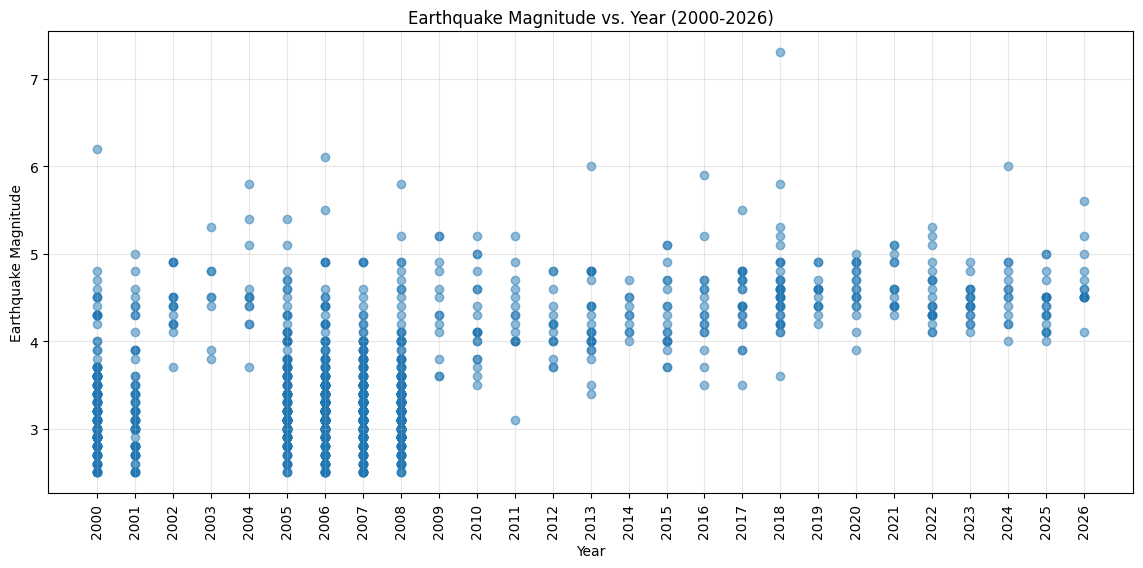

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14,6))
#plot each quake as an individual point
# plt.scatter(x values, y values, aplha 0.5 - makes points transparent)
plt.scatter(earthquakes["year"],earthquakes["mag"], alpha=0.5)

plt.xlabel("Year")
plt.ylabel("Earthquake Magnitude")
plt.title("Earthquake Magnitude vs. Year (2000-2026)")

plt.grid(alpha=0.3)
plt.xticks(range(2000,2027,1),rotation=90)
plt.grid(axis="x", alpha=0.3)
plt.savefig("Earthquake_Magnitude_vs_Year.png",dpi=300, bbox_inches="tight")
plt.show

In [ ]:
annual_counts = earthquakes["year"].value_counts().sort_index()

print(annual_counts)

year
2000    142
2001     66
2002     15
2003      8
2004     12
2005    144
2006    212
2007    251
2008    191
2009     13
2010     19
2011     15
2012     15
2013     24
2014     10
2015     19
2016     17
2017     21
2018     36
2019     13
2020     18
2021     14
2022     21
2023     17
2024     14
2025     19
2026     14
Name: count, dtype: int64


In [ ]:
yearly_summary = earthquakes.groupby("year")["mag"].agg(["count", "min", "max"])
#.groupby("year") separates the earthquakes by year
# .agg() calculates the count, minimum and maximum magnitude for each yea
print(yearly_summary)

      count  min  max
year                 
2000    142  2.5  6.2
2001     66  2.5  5.0
2002     15  3.7  4.9
2003      8  3.8  5.3
2004     12  3.7  5.8
2005    144  2.5  5.4
2006    212  2.5  6.1
2007    251  2.5  4.9
2008    191  2.5  5.8
2009     13  3.6  5.2
2010     19  3.5  5.2
2011     15  3.1  5.2
2012     15  3.7  4.8
2013     24  3.4  6.0
2014     10  4.0  4.7
2015     19  3.7  5.1
2016     17  3.5  5.9
2017     21  3.5  5.5
2018     36  3.6  7.3
2019     13  4.2  4.9
2020     18  3.9  5.0
2021     14  4.3  5.1
2022     21  4.1  5.3
2023     17  4.1  4.9
2024     14  4.0  6.0
2025     19  4.0  5.0
2026     14  4.1  5.6


In [ ]:
network_summary = pd.crosstab(
    earthquakes["year"],
    earthquakes["net"]
)

print(network_summary.loc[[2007, 2008, 2009, 2019, 2025]])

net    us
year     
2007  251
2008  191
2009   13
2019   13
2025   19


In [ ]:
all_counts = earthquakes.groupby("year").size()

large_counts = earthquakes[
    earthquakes["mag"] >= 4.5
].groupby("year").size()

comparison = pd.DataFrame({
    "All earthquakes": all_counts,
    "Magnitude 4.5+": large_counts
}).fillna(0).astype(int)

print(comparison.loc[2005:2012])

      All earthquakes  Magnitude 4.5+
year                                 
2005              144               8
2006              212               8
2007              251               5
2008              191               9
2009               13               6
2010               19               6
2011               15               5
2012               15               3


annual earthquake frequency plot

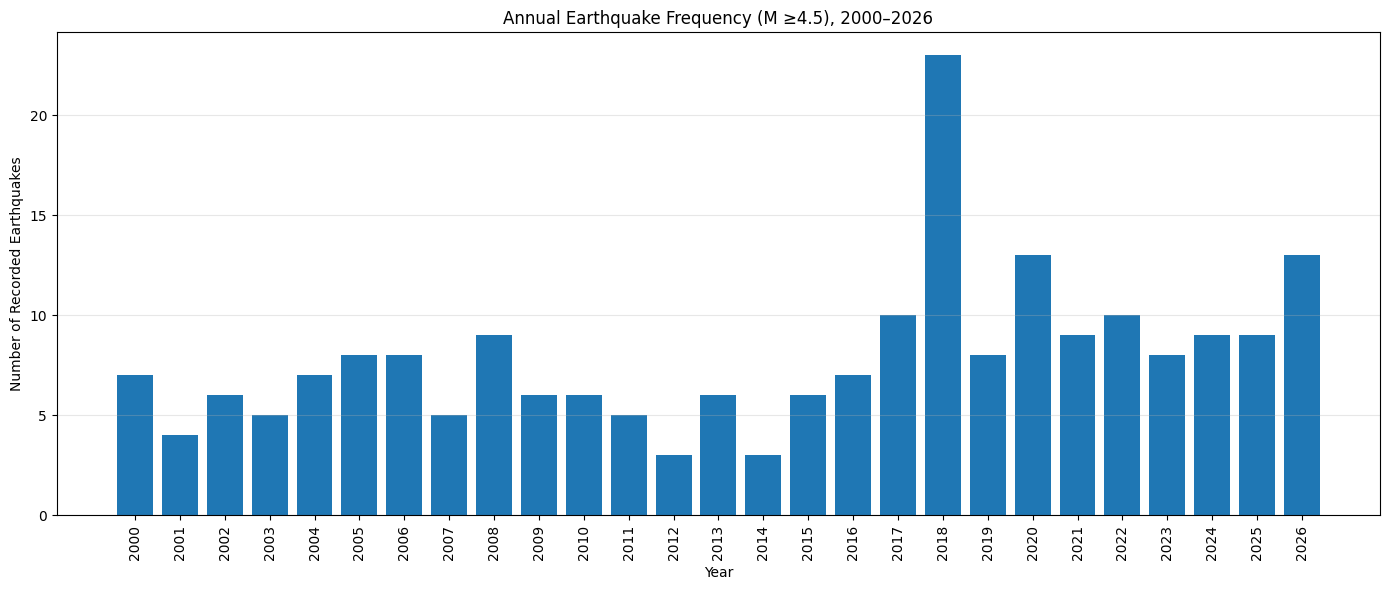

In [ ]:
large_earthquakes = earthquakes[earthquakes["mag"] >= 4.5]

annual_counts_45 = large_earthquakes.groupby("year").size()

annual_counts_45 = annual_counts_45.reindex(
    range(2000, 2027), fill_value=0
)
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.bar(annual_counts_45.index, annual_counts_45.values)

plt.xlabel("Year")
plt.ylabel("Number of Recorded Earthquakes")
plt.title("Annual Earthquake Frequency (M ≥4.5), 2000–2026")

plt.xticks(range(2000, 2027), rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig("Annual_Earthquake_Frequency_M45.png",
            dpi=300, bbox_inches="tight")

plt.show()

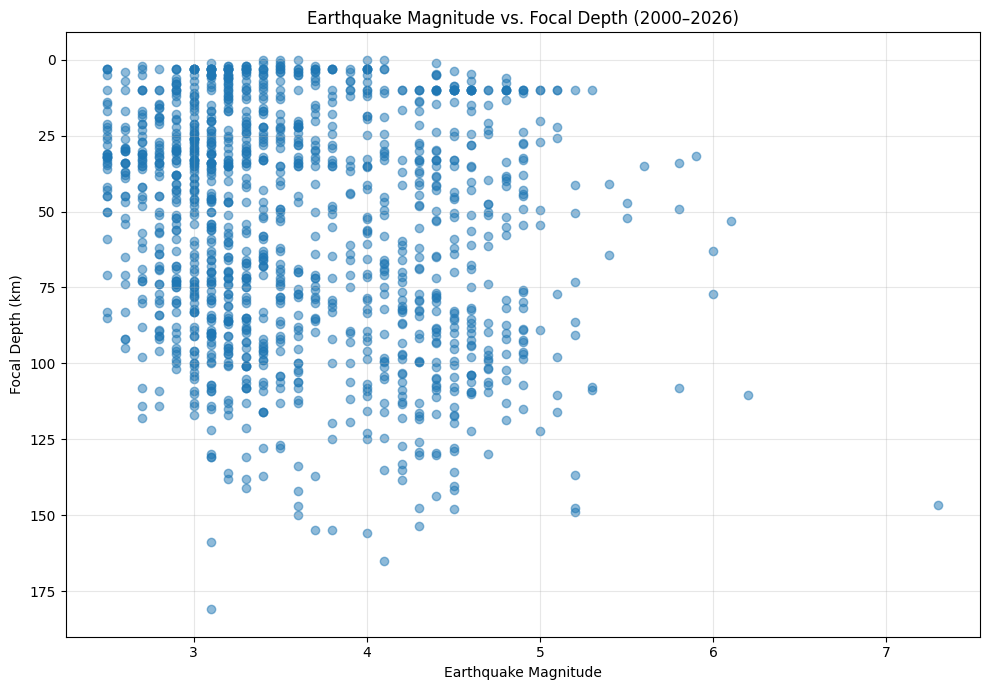

In [ ]:
plt.figure(figsize=(10, 7))

plt.scatter(
    earthquakes["mag"],
    earthquakes["depth"],
    alpha=0.5
)

plt.xlabel("Earthquake Magnitude")
plt.ylabel("Focal Depth (km)")
plt.title("Earthquake Magnitude vs. Focal Depth (2000–2026)")

plt.gca().invert_yaxis()

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("Magnitude_vs_Depth.png", dpi=300,
            bbox_inches="tight")

plt.show()

Earthquakes selected: 1292


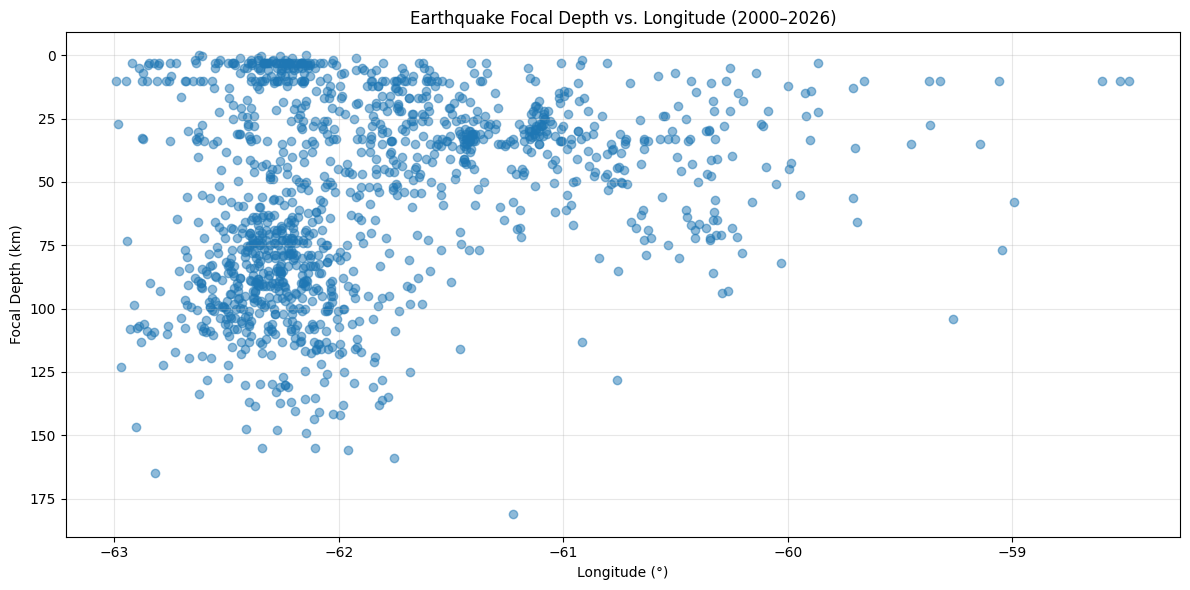

In [ ]:

# PLOT 4: EARTHQUAKE FOCAL DEPTH VS. LONGITUDE
# Objective: Investigate whether earthquake focal depths
# generally increase westward across the study region.

import matplotlib.pyplot as plt

# STEP 1: FILTER THE DATASET

# Select earthquakes between 10°N and 12°N latitude.
# .between(10, 12) includes both boundary values.
# This reduces the geographic area being analysed.
# We save the filtered data in a new variable.
regional_eq = earthquakes[
    earthquakes["latitude"].between(10, 12)
]

# Check how many earthquakes satisfy our filter.
# len() counts the number of rows in the filtered dataset.
print("Earthquakes selected:", len(regional_eq))


# STEP 2: CREATE THE FIGURE

# Set the figure dimensions in inches.
plt.figure(figsize=(12, 6))

# Create a scatter plot.
# Each point represents one earthquake.
# X-axis: Longitude (geographic position)
# Y-axis: Focal depth in kilometres
# alpha=0.5 makes overlapping points easier to see.
plt.scatter(
    regional_eq["longitude"],
    regional_eq["depth"],
    alpha=0.5
)


# STEP 3: FORMAT THE GRAPH

# Add descriptive axis labels and a title.
plt.xlabel("Longitude (°)")
plt.ylabel("Focal Depth (km)")
plt.title("Earthquake Focal Depth vs. Longitude (2000–2026)")

# Reverse the Y-axis so shallow earthquakes appear
# at the top and deeper earthquakes at the bottom.
plt.gca().invert_yaxis()

# Add gridlines to help read values.
plt.grid(alpha=0.3)

# Automatically adjust spacing to prevent overlapping labels.
plt.tight_layout()


# STEP 4: SAVE AND DISPLAY

# Save a high-resolution PNG for the project report.
# 300 dpi produces a suitable image for documents.
# bbox_inches="tight" helps prevent labels being cut off.
plt.savefig(
    "Depth_vs_Longitude.png",
    dpi=300,
    bbox_inches="tight"
)

# Display the completed graph.
plt.show()


**Purpose of analysis**

This plot investigates the relationship between earthquake focal depth and longitude within the 10–12°N latitude band surrounding Trinidad and Tobago.

Negative longitudes represent positions west of the Prime Meridian. Therefore, increasingly negative longitude values indicate locations farther west.

The analysis aims to identify whether deeper earthquakes occur farther west, reflecting the westward-dipping Atlantic lithosphere beneath the Caribbean Plate.

**Limitations**

The analysis does not account for the arcuate, three-dimensional geometry of the Lesser Antilles subduction system, variations in slab dip, or the presence of multiple tectonic regimes.

Consequently, any observed westward deepening should be considered a preliminary spatial association rather than definitive evidence of slab geometry.

In [ ]:
# Check the geographic limits of our selected earthquakes

print("Minimum longitude:", regional_eq["longitude"].min())
print("Maximum longitude:", regional_eq["longitude"].max())

print("Minimum latitude:", regional_eq["latitude"].min())
print("Maximum latitude:", regional_eq["latitude"].max())

Minimum longitude: -62.9908
Maximum longitude: -58.478
Minimum latitude: 10.002
Maximum latitude: 11.964


Principal Component Analysis

In [ ]:
#examining earthquake spatial distribution

import matplotlib.pyplot as plt

#check that our original dataset is still loaded
print("Total earthquakes:", len(earthquakes))



Total earthquakes: 1360


In [ ]:
import pandas as pd

earthquakes=pd.read_csv("TT_Earthquakes_for_Python.csv")

print("Total Earthquakes:", len(earthquakes))

Total Earthquakes: 1360


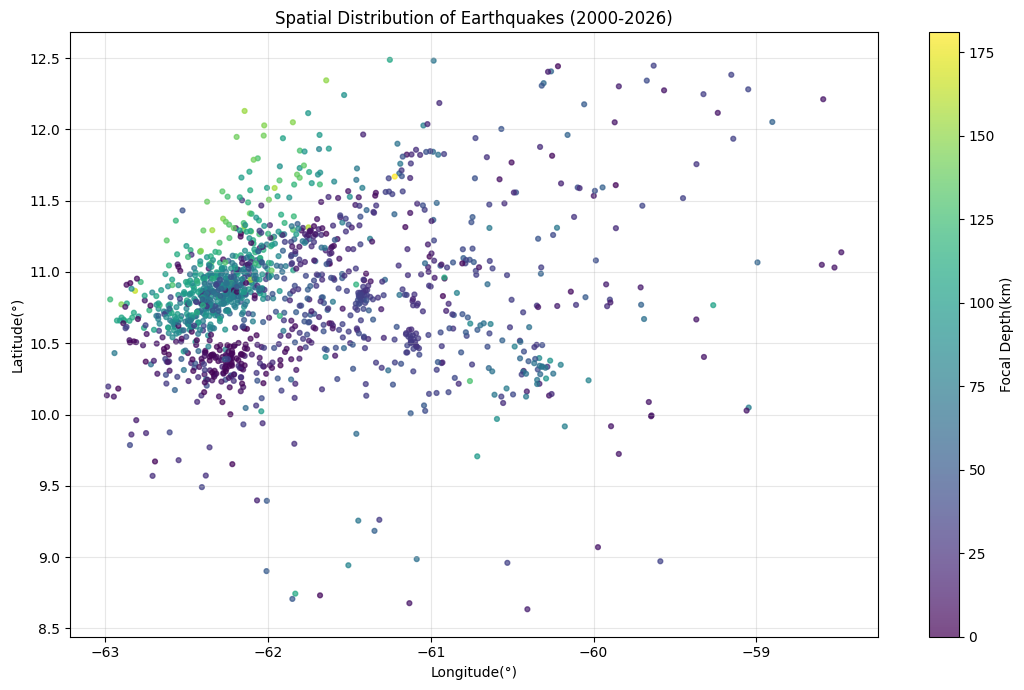

In [ ]:
#Create Figure to examine locations

plt.figure(figsize=(11,7))

#plot longitude on the x latitide on the y
#each point represents one earthquake epicentre
#colour represents focal depth in km

plt.scatter(
    earthquakes["longitude"],
    earthquakes["latitude"],
    c=earthquakes["depth"],
    cmap="viridis",
    s=12,
    alpha=0.7
)

#Add colour scale showing earthquake depth

plt.colorbar(label="Focal Depth(km)")

#label the axes and figs

plt.xlabel("Longitude(°)")
plt.ylabel("Latitude(°)")
plt.title("Spatial Distribution of Earthquakes (2000-2026)")
plt.grid(alpha=0.3)

#adjust spacing and displa the graph
plt.savefig("Spatial Distribution of Earthquakes (2000-2026).png", dpi=300,
            bbox_inches="tight")
plt.tight_layout()
plt.show()

In [ ]:
# change of plan, i want to mathematiclly identify clusters
# rather than via observation
#Investigation 1 :DBSCAN earthquale clustering
#objective: identify spatial concentrations of earthquake
#epicentres using a methematical clustering method

import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN

#1: prepare equake data
# create a separate dataset for clustering
# remove any observations with missing coordinates
# .copy() keeps our orginal dataset unchanged

clustered_eq =earthquakes.dropna(subset=["latitude", "longitude"]).copy()

print("Earthquakes available:", len(clustered_eq))


Earthquakes available: 1360


In [ ]:
#2 : select latitude and longitude in that order
# the haversine distance calculation requires this order
coordinates = clustered_eq[["latitude", "longitude"]]

#convert geographic coords from degrees to radians
#radians and the angular units required by haversine calculations

coordinates_rad = np.radians(coordinates)

#3 define our clustering parameters
#max neighbourhood distance in km

distance_km=20

#approx radius of earth in km
earth_radius_km=6371

# convert our 20km distance to angular distance
epsilion= distance_km/earth_radius_km

#run dbscan
# min_samples=10 requires at least 10 observations in
# a neighbourhood, including the central observation
# metric="haversine" calculates geographic distances

dbscan = DBSCAN(
    eps=epsilion,
    min_samples=10,
    metric="haversine",
    algorithm="ball_tree"
)
# Run the algorithm and assign each earthquake a cluster ID.
clustered_eq["cluster"] = dbscan.fit_predict(coordinates_rad)

#5 examine results
#count how many earthquakes belong in each cluster
print("Earthquakes per cluster:")
print(clustered_eq["cluster"].value_counts().sort_index())

Earthquakes per cluster:
cluster
-1     133
 0    1227
Name: count, dtype: int64


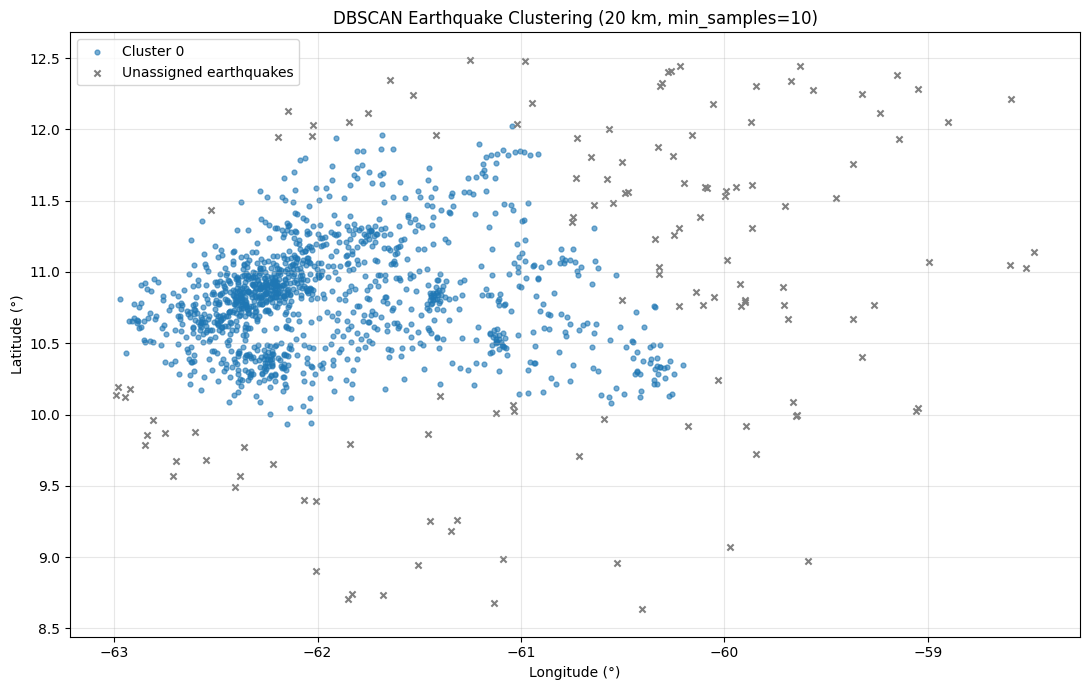

In [ ]:

# DBSCAN - VISUALISING CLUSTER RESULTS
# Objective: Examine the spatial distribution of
# clustered and unassigned earthquakes.

import matplotlib.pyplot as plt

# Separate earthquakes by their DBSCAN classification.
# Cluster 0 contains earthquakes assigned to the cluster.
cluster_0 = clustered_eq[clustered_eq["cluster"] == 0]

# Cluster -1 contains unassigned observations (noise).
noise = clustered_eq[clustered_eq["cluster"] == -1]

# Create a scatter plot.
plt.figure(figsize=(11, 7))

# Plot earthquakes belonging to Cluster 0.
plt.scatter(
    cluster_0["longitude"],
    cluster_0["latitude"],
    s=12,
    alpha=0.6,
    label="Cluster 0"
)

# Plot unassigned earthquakes separately.
plt.scatter(
    noise["longitude"],
    noise["latitude"],
    s=20,
    marker="x",
    color="gray",
    label="Unassigned earthquakes"
)

# Add labels and formatting.
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.title("DBSCAN Earthquake Clustering (20 km, min_samples=10)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



In [ ]:

# DBSCAN SENSITIVITY ANALYSIS
# Objective: Investigate how neighbourhood distance
# affects the number of identified earthquake clusters.

# We are keeping min_samples constant at 10.
# Only the neighbourhood distance will change.

distances_km = [5, 10, 15, 20]

for distance in distances_km:

    # Convert the distance from kilometres to radians.
    epsilon = distance / 6371

    # Run DBSCAN using the current distance.
    model = DBSCAN(
        eps=epsilon,
        min_samples=10,
        metric="haversine",
        algorithm="ball_tree"
    )

    # Assign each earthquake a cluster label.
    labels = model.fit_predict(coordinates_rad)

    # Count the clusters, excluding noise (-1).
    number_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    # Count earthquakes classified as noise.
    number_noise = (labels == -1).sum()

    # Display results for this distance.
    print("Distance:", distance, "km")
    print("Clusters identified:", number_clusters)
    print("Unassigned earthquakes:", number_noise)
    print("----------------------------")


Distance: 5 km
Clusters identified: 6
Unassigned earthquakes: 881
----------------------------
Distance: 10 km
Clusters identified: 8
Unassigned earthquakes: 419
----------------------------
Distance: 15 km
Clusters identified: 5
Unassigned earthquakes: 187
----------------------------
Distance: 20 km
Clusters identified: 1
Unassigned earthquakes: 133
----------------------------


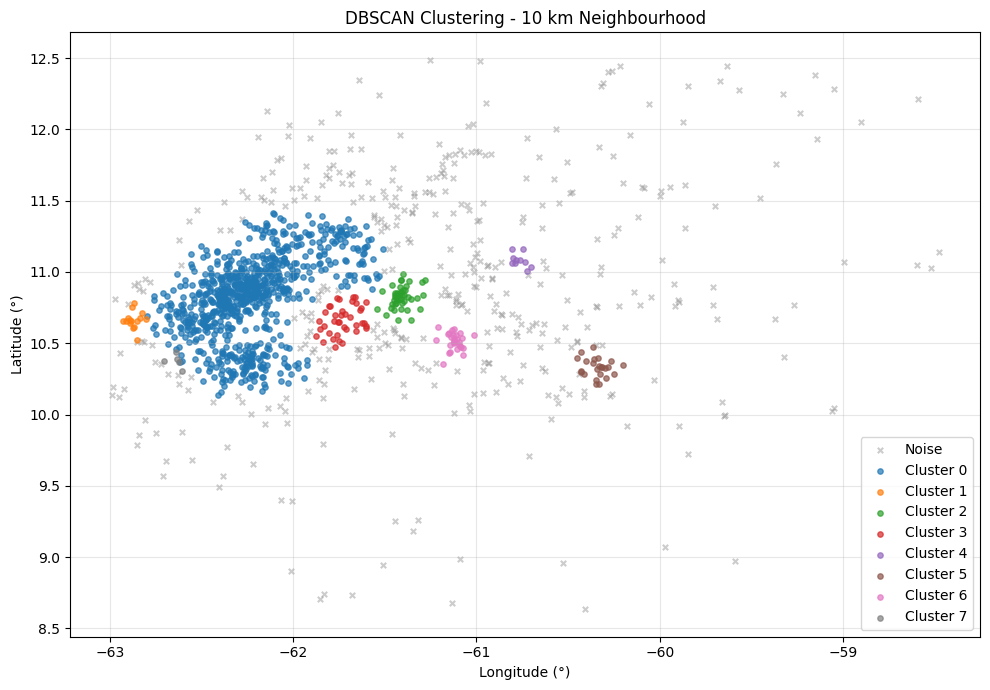

In [ ]:

# DBSCAN - VISUALISING THE 10 KM RESULTS
# Objective: Examine the eight clusters identified
# using a 10 km neighbourhood and min_samples=10.

import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN

# Run DBSCAN with a 10 km neighbourhood.
# Coordinates were previously converted to radians.
model_10 = DBSCAN(
    eps=10 / 6371,
    min_samples=10,
    metric="haversine",
    algorithm="ball_tree"
)

# Store the resulting cluster labels.
clustered_eq["cluster_10"] = model_10.fit_predict(coordinates_rad)

# Create the figure.
plt.figure(figsize=(10, 7))

# Plot each identified cluster separately.
# Noise (-1) will be shown as grey crosses.
for cluster_id in sorted(clustered_eq["cluster_10"].unique()):

    group = clustered_eq[
        clustered_eq["cluster_10"] == cluster_id
    ]

    if cluster_id == -1:
        plt.scatter(
            group["longitude"], group["latitude"],
            color="gray", marker="x", s=15,
            alpha=0.4, label="Noise"
        )
    else:
        plt.scatter(
            group["longitude"], group["latitude"],
            s=15, alpha=0.7,
            label=f"Cluster {cluster_id}"
        )

# Add labels and formatting.
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.title("DBSCAN Clustering - 10 km Neighbourhood")

plt.legend()
plt.grid(alpha=0.3)
plt.savefig("DBSCAN Clustering - 10 km Neighbourhood.png", dpi=300,
            bbox_inches="tight")
plt.tight_layout()
plt.show()


15 km cluster counts:
cluster_15
-1     187
 0    1068
 1      38
 2      19
 3      33
 4      15
Name: count, dtype: int64


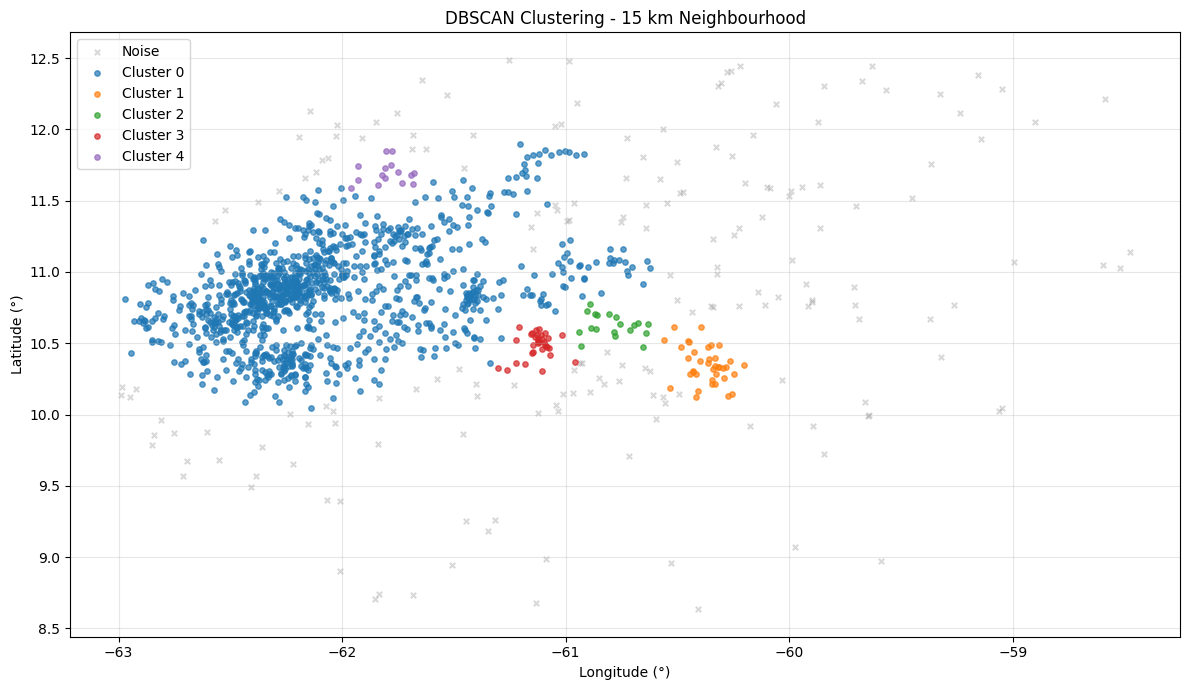

In [ ]:

# DBSCAN: 15 KM NEIGHBOURHOOD
# Objective: Compare spatial clustering at 15 km
# against our previous 10 km results.

# STEP 1: RUN DBSCAN

# eps = 15 km converted to radians.
# min_samples remains at 10 for comparison.
model_15 = DBSCAN(
    eps=15 / 6371,
    min_samples=10,
    metric="haversine",
    algorithm="ball_tree"
)

# Store the results in a NEW column.
# This preserves our previous 10 km cluster labels.
clustered_eq["cluster_15"] = model_15.fit_predict(coordinates_rad)


# STEP 2: DISPLAY CLUSTER COUNTS

print("15 km cluster counts:")
print(clustered_eq["cluster_15"].value_counts().sort_index())


# STEP 3: PLOT THE CLUSTERS

plt.figure(figsize=(12, 7))

# Loop through each identified cluster.
for cluster_id in sorted(clustered_eq["cluster_15"].unique()):

    # Select earthquakes belonging to this cluster.
    group = clustered_eq[
        clustered_eq["cluster_15"] == cluster_id
    ]

    if cluster_id == -1:
        # Plot unassigned earthquakes as grey crosses.
        plt.scatter(
            group["longitude"],
            group["latitude"],
            color="gray",
            marker="x",
            s=15,
            alpha=0.3,
            label="Noise"
        )

    else:
        # Plot identified clusters separately.
        plt.scatter(
            group["longitude"],
            group["latitude"],
            s=15,
            alpha=0.7,
            label=f"Cluster {cluster_id}"
        )

# STEP 4: FORMAT AND DISPLAY

plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.title("DBSCAN Clustering - 15 km Neighbourhood")

plt.legend()
plt.grid(alpha=0.3)
plt.savefig("DBSCAN Clustering - 15 km Neighbourhood.png", dpi=300,
            bbox_inches="tight")
plt.tight_layout()
plt.show()


In [ ]:

# DBSCAN: CLUSTER DEPTH ANALYSIS
# Objective: Compare the depth characteristics of
# clusters identified using 10 km and 15 km radii.

for distance in [10, 15]:

    # Select the cluster labels for this distance.
    column = f"cluster_{distance}"

    # Group earthquakes by their assigned cluster.
    # Calculate the number of events and depth statistics.
    summary = clustered_eq.groupby(column).agg(
        earthquake_count=("depth", "size"),
        minimum_depth=("depth", "min"),
        median_depth=("depth", "median"),
        maximum_depth=("depth", "max")
    )

    # Print a separate summary for each radius.
    print(f"\nDBSCAN RESULTS: {distance} KM")
    print(summary.round(1))



DBSCAN RESULTS: 10 KM
            earthquake_count  minimum_depth  median_depth  maximum_depth
cluster_10                                                              
-1                       419            2.0          35.0          181.0
 0                       776            0.0          71.0          159.0
 1                        15            3.0         106.1          113.2
 2                        44            3.0          33.5          116.0
 3                        39            3.0          34.0           73.0
 4                        10            3.0          38.0           53.0
 5                        24           10.0          66.0           94.0
 6                        28           22.0          30.5           47.0
 7                         5            2.9          16.4           34.0

DBSCAN RESULTS: 15 KM
            earthquake_count  minimum_depth  median_depth  maximum_depth
cluster_15                                                              
-1   

In [ ]:

# DBSCAN VALIDATION
# Objective: Confirm that our 10 km cluster labels
# correspond to min_samples=10.

# Recreate the coordinates from the current DataFrame.
# Haversine requires latitude first, then longitude.
coordinates_rad = np.radians(
    clustered_eq[["latitude", "longitude"]]
)

# Run DBSCAN again using the intended parameters.
check_model = DBSCAN(
    eps=10 / 6371,
    min_samples=10,
    metric="haversine",
    algorithm="ball_tree"
)

# Store the validated cluster assignments.
clustered_eq["cluster_10"] = check_model.fit_predict(
    coordinates_rad
)

# Count earthquakes in each cluster.
print(clustered_eq["cluster_10"].value_counts().sort_index())



cluster_10
-1    419
 0    776
 1     15
 2     44
 3     39
 4     10
 5     24
 6     28
 7      5
Name: count, dtype: int64


In [ ]:
# Identify the cluster labels of all core points
core_labels = check_model.labels_[check_model.core_sample_indices_]

# Count core points belonging to Cluster 7
print("Core points in Cluster 7:", (core_labels == 7).sum())

Core points in Cluster 7: 2
